In [1]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [5]:
target_region_list = ['Wash_bay', 'Henber', 'Thames_esturay', 'Region3b1', 'Solway', 
                      'Morecambe', 'ribble', 'Severn_Esturay', 'Region4b', 'Region4a4']
for j in range(len(target_region_list)):
    
    target_region = target_region_list[j]
    print(target_region)

Wash_bay
Henber
Thames_esturay
Region3b1
Solway
Morecambe
ribble
Severn_Esturay
Region4b
Region4a4


In [6]:
import geopandas as gpd
import pandas as pd
import os
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
num = 0
for year in year_list:
    num = 0
    ICESat_point_path = f'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_{year}_combine2.shp'
    k = gpd.read_file(ICESat_point_path)
    k.columns
    
    num += len(k['Strip_No'].unique())
    print(num)

443
453
447
489
440
383


In [3]:
import geopandas as gpd
import pandas as pd
import os

Region_list = ['Region1', 'Region2', 'Region3','Region4', 'Region5','Region6']
location_list = [['Thames', 'Region1a', 'Region1b', 'Region1c'],
                 ['wash_bay', 'Henber', 'Region2a'],
                 ['Region3a1','Region3b1', 'Region3b2', 'Region3c', 'Region3d'],
                 ['Solway', 'Morecambe', 'Region4c', 'Region4d','Ribble', 'Severn','Region4b', 'Region4a1', 'Region4a2', 'Region4a3', 'Region4a4'],
                 ['Region5b','Region5c','Region5d','Region5e','Region5f','Region5g','Region5h','Region5i'],
                 ['Region6d', 'Region6e','Region6f','Region6g','Region6h','Region6i','Region6j']]

year_list = [2019, 2020, 2021, 2022, 2023, 2024]

# 可以统一指定目标 CRS，例如 WGS84
target_crs = "EPSG:4326"

for year in year_list:
    output_path = f'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_{year}_combine2.shp'
    
    # 创建空的 GeoDataFrame
    merged_gdf = gpd.GeoDataFrame(columns=['OH', 'geometry', 'Strip_No'], crs=target_crs)
    
    for i in range(len(Region_list)):
        Region = Region_list[i]
        for location in location_list[i]:
            ICESat_point_path = f'G:\\ICESat-2\\{Region}_map\\{location}_map\\A{year}\\A_{location}_30m_{year}_new10.shp'
            
            gdf = gpd.read_file(ICESat_point_path)[['OH', 'geometry','Strip_No']]
            
            # 转换 CRS 到目标 CRS
            gdf = gdf.to_crs(target_crs)
            
            # 合并
            merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)

    # 创建输出目录
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    # 保存 shapefile
    merged_gdf.to_file(output_path)
    print(f'Merged shapefile saved to {output_path}')


C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\1561881411.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)


Merged shapefile saved to G:\ICESat-2\ICESat_points_combine\ICESat_R1234_2019_combine2.shp


C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\1561881411.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)


Merged shapefile saved to G:\ICESat-2\ICESat_points_combine\ICESat_R1234_2020_combine2.shp


C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\1561881411.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)


Merged shapefile saved to G:\ICESat-2\ICESat_points_combine\ICESat_R1234_2021_combine2.shp


... (2 outputs left out)

C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\1561881411.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)


Merged shapefile saved to G:\ICESat-2\ICESat_points_combine\ICESat_R1234_2023_combine2.shp


C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\1561881411.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=target_crs)


Merged shapefile saved to G:\ICESat-2\ICESat_points_combine\ICESat_R1234_2024_combine2.shp


In [2]:
import geopandas as gpd
import pandas as pd
import os

Region_list = ['Region1', 'Region2', 'Region3','Region4', 'Region5','Region6']
location_list = [['Thames', 'Region1a', 'Region1b', 'Region1c'],
                 ['wash_bay', 'Henber', 'Region2a'],
                 ['Region3a1','Region3b1', 'Region3b2', 'Region3c'],
                 ['Solway', 'Morecambe', 'Region4c', 'Region4d','Ribble', 'Severn','Region4b', 'Region4a1', 'Region4a2', 'Region4a3', 'Region4a4'],
                 ['Region5b','Region5c','Region5d','Region5e','Region5f','Region5g','Region5h','Region5i'],
                 ['Region6d','Region6e','Region6f','Region6g','Region6h','Region6i','Region6j']]

year_list = [2019, 2020, 2021, 2022, 2023, 2024]
for year in year_list:

    output_path = f'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_{year}_combine2.shp'
    # 创建一个空的 GeoDataFrame，用于存储合并后的点
    merged_gdf = gpd.GeoDataFrame(columns=['OH', 'geometry'])
    for i in range(len(Region_list)):
        
        Region = Region_list[i]
        for location in location_list[i]:
            ICESat_point_path = f'G:\\ICESat-2\\{Region}_map\\{location}_map\\A{year}\\A_{location}_30m_{year}_new10.shp'
            gdf = gpd.read_file(ICESat_point_path)[['OH', 'geometry']]  # 只保留需要的列
            merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=gdf.crs)

    # 输出路径
    output_path = output_path
    os.makedirs(os.path.dirname(output_path), exist_ok=True)

    # 导出为shp文件
    merged_gdf.to_file(output_path)

    print(f'Merged shapefile saved to {output_path}')


C:\Users\minyu\AppData\Local\Temp\ipykernel_22856\4270650675.py:25: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  merged_gdf = gpd.GeoDataFrame(pd.concat([merged_gdf, gdf], ignore_index=True), crs=gdf.crs)


ValueError: Cannot determine common CRS for concatenation inputs, got ['WGS 84 / UTM zone 30N', 'WGS 84 / UTM zone 31N']. Use `to_crs()` to transform geometries to the same CRS before merging.

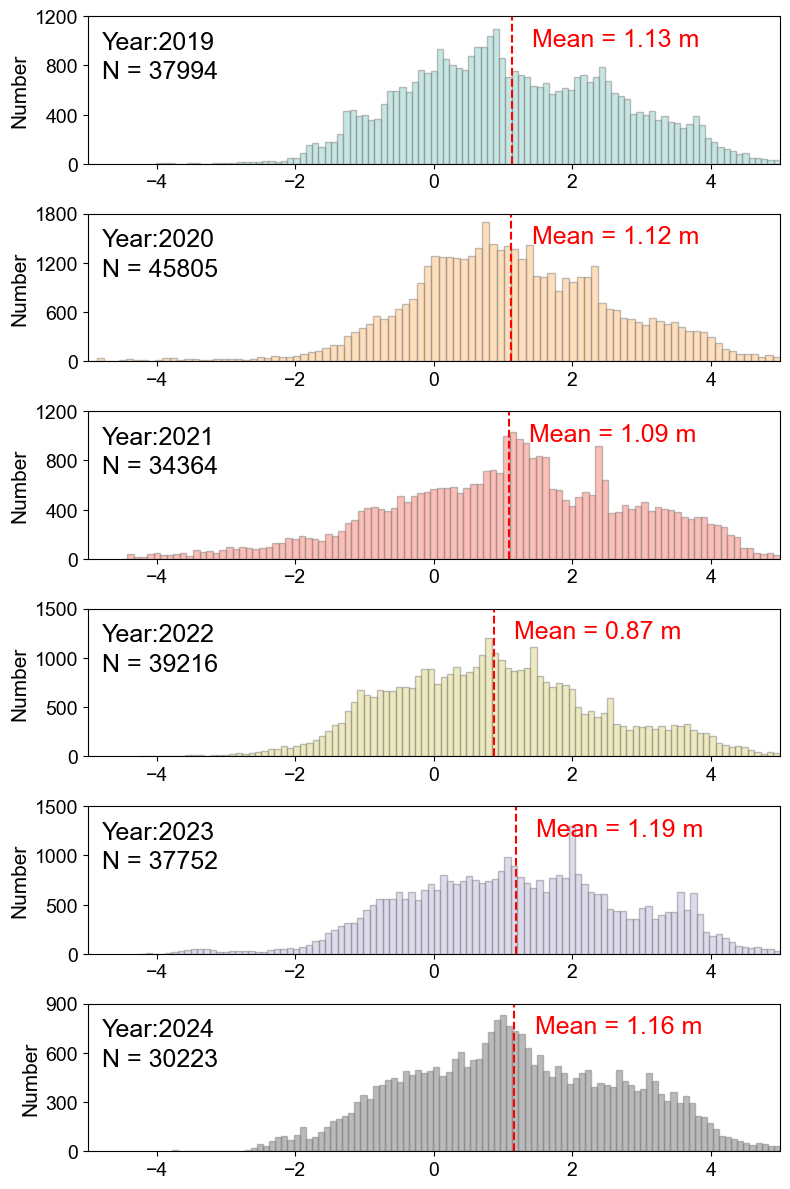

In [28]:
import matplotlib.pyplot as plt
import geopandas as gpd
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
import numpy as np

# 创建图像与6个子图
fig, axes = plt.subplots(nrows=6, figsize=(8, 12), gridspec_kw={'height_ratios': [1]*6})

# 所有shapefile路径
paths = [
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2019_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2020_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2021_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2022_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2023_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2024_combine2.shp'
]

# 对应的颜色
colors = ['#8ECFC9', '#FFBE7A', '#FA7F6F', "#DFD783",  '#BEB8DC', "#787474"]
ylim_range_list = [[0, 1200], [0,1800], [0, 1200], [0,1500], [0, 1500], [0, 900]]
yticks_range_list = [np.arange(0, 1201, 400),np.arange(0, 1801, 600), np.arange(0, 1201, 400), np.arange(0, 1501, 500), np.arange(0, 1501, 500), np.arange(0, 901, 300)]
bin_count = 100
xlim_range = [-5, 5]
ylabel = 'Number'
year_list = [2019, 2020, 2021, 2022, 2023, 2024]
# 循环读取数据、绘图
for i, (ax, path, color) in enumerate(zip(axes, paths, colors)):
    gdf = gpd.read_file(path)
    data = gdf['OH'].dropna()

    # 画直方图
    ax.hist(data, bins=bin_count, color=color, edgecolor='gray', alpha=0.5)

    # 设置x轴范围
    ax.set_xlim(xlim_range)
    ax.set_yticks(yticks_range_list[i])
    # 设置y轴标签
    ax.set_ylabel(ylabel, fontsize = 15)
    ax.tick_params(axis='both', labelsize=14)
    # 均值线及文字
    mean_val = np.mean(data)
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5)
    ax.text(mean_val+1.5, ax.get_ylim()[1]*0.8, f'Mean = {mean_val:.2f} m', 
            color='red', ha='center', fontsize=18)
    ax.text(-4.8, ax.get_ylim()[1]*0.70, f'N = {len(data)}', fontsize=18, ha='left', va='top')
    ax.text(-4.8, ax.get_ylim()[1]*0.90, f'Year:{year_list[i]}', fontsize=18, ha='left', va='top')
# 自动调整布局
plt.tight_layout()
plt.show()


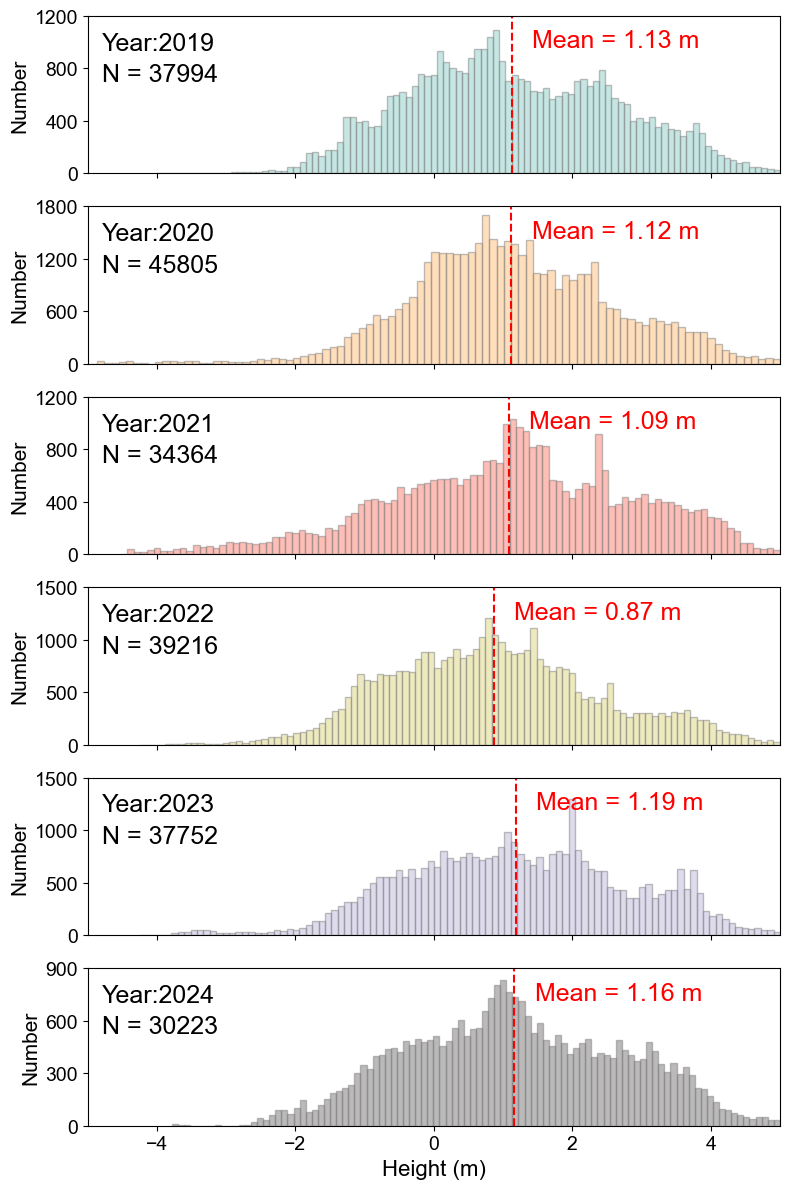

In [30]:
import matplotlib.pyplot as plt
import geopandas as gpd
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
import numpy as np

# 创建图像与6个子图（共享x轴）
fig, axes = plt.subplots(
    nrows=6, figsize=(8, 12),
    gridspec_kw={'height_ratios': [1]*6},
    sharex=True
)

# 所有shapefile路径
paths = [
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2019_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2020_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2021_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2022_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2023_combine2.shp',
    'G:\\ICESat-2\\ICESat_points_combine\\ICESat_R1234_2024_combine2.shp'
]

# 对应的颜色
colors = ['#8ECFC9', '#FFBE7A', '#FA7F6F', "#DFD783",  '#BEB8DC', "#787474"]
ylim_range_list = [
    [0, 1200], [0,1800], [0, 1200],
    [0,1500], [0, 1500], [0, 900]
]
yticks_range_list = [
    np.arange(0, 1201, 400),
    np.arange(0, 1801, 600),
    np.arange(0, 1201, 400),
    np.arange(0, 1501, 500),
    np.arange(0, 1501, 500),
    np.arange(0, 901, 300)
]
bin_count = 100
xlim_range = [-5, 5]
ylabel = 'Number'
year_list = [2019, 2020, 2021, 2022, 2023, 2024]

# 循环读取数据、绘图
for i, (ax, path, color) in enumerate(zip(axes, paths, colors)):
    gdf = gpd.read_file(path)
    data = gdf['OH'].dropna()

    # 画直方图
    ax.hist(data, bins=bin_count, color=color, edgecolor='gray', alpha=0.5)

    # 设置坐标范围
    ax.set_xlim(xlim_range)
    ax.set_yticks(yticks_range_list[i])

    # 设置y轴标签
    ax.set_ylabel(ylabel, fontsize=15)
    ax.tick_params(axis='both', labelsize=14)

    # 均值线及文字
    mean_val = np.mean(data)
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5)
    ax.text(mean_val+1.5, ax.get_ylim()[1]*0.8, f'Mean = {mean_val:.2f} m',
            color='red', ha='center', fontsize=18)
    ax.text(-4.8, ax.get_ylim()[1]*0.70, f'N = {len(data)}',
            fontsize=18, ha='left', va='top')
    ax.text(-4.8, ax.get_ylim()[1]*0.90, f'Year:{year_list[i]}',
            fontsize=18, ha='left', va='top')

    # 只保留最后一张的 x 轴刻度
    if i < len(axes) - 1:
        ax.tick_params(axis='x', labelbottom=False)

# 给最后一张加 x 轴标题
axes[-1].set_xlabel("Height (m)", fontsize=16)

# 自动调整布局
plt.tight_layout()
plt.show()


In [ ]:
paths

In [32]:
len(data)

24536

In [32]:
import geopandas as gpd
import pandas as pd
import os

    
ICESat_point_path = f'E:\GEE_download\Merge_imgs\S2_YC_median3_points.shp'
k = gpd.read_file(ICESat_point_path)
k.columns
# num += len(k['Strip_No'].unique())

Index(['Id', 'class', 'b1_S2_YC_M', 'b2_S2_YC_M', 'b3_S2_YC_M', 'b4_S2_YC_M',
       'b5_S2_YC_M', 'b6_S2_YC_M', 'b7_S2_YC_M', 'b8_S2_YC_M', 'b9_S2_YC_M',
       'b10_S2_YC_', 'b11_S2_YC_', 'b12_S2_YC_', 'b13_S2_YC_', 'b14_S2_YC_',
       'b15_S2_YC_', 'b16_S2_YC_', 'b1_S2_', 'b2_S2_', 'b3_S2_', 'b4_S2_',
       'b5_S2_', 'b6_S2_', 'b7_S2_', 'b8_S2_', 'b9_S2_', 'b10_S2_', 'b11_S2_',
       'b12_S2_', 'b13_S2_', 'b14_S2_', 'b15_S2_', 'b16_S2_', 'geometry'],
      dtype='object')

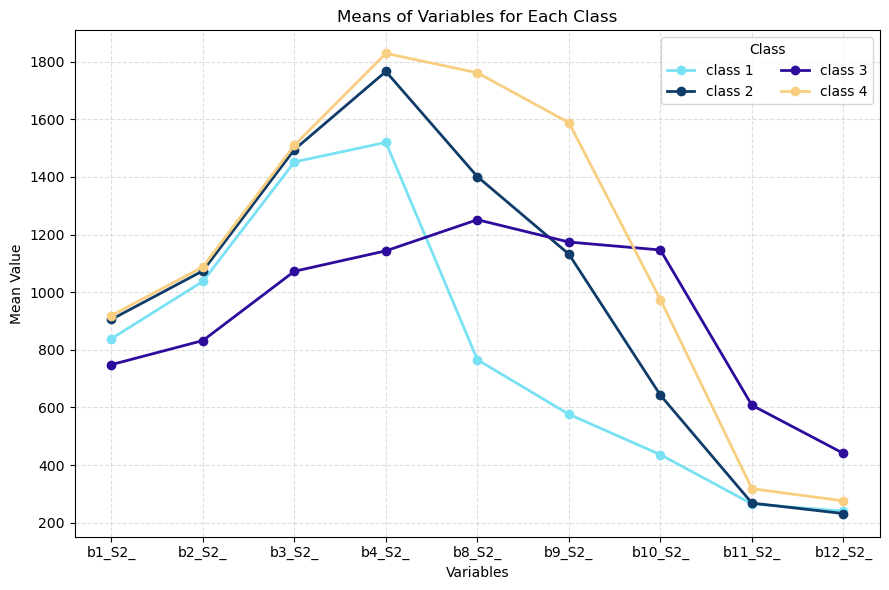

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 1) 选择变量 ---
vars_to_plot = ['b1_S2_Solw','b2_S2_Solw','b3_S2_Solw','b4_S2_Solw','b5_S2_Solw','b6_S2_Solw','b7_S2_Solw','b8_S2_Solw','b9_S2_Solw','b10_S2_Sol','b11_S2_Sol','b12_S2_Sol']
vars_to_plot = ['b2_S2_Wash', 'b3_S2_Wash', 'b4_S2_Wash','b8_S2_Wash','b9_S2_Wash','b10_S2_Was','b11_S2_Was','b12_S2_Was']
vars_to_plot = ['b13_S2_Was']
vars_to_plot = ['b1_S2_', 'b2_S2_', 'b3_S2_', 'b4_S2_','b8_S2_', 'b9_S2_', 'b10_S2_', 'b11_S2_','b12_S2_']
# --- 2) 按 class 分组求均值 ---
df = k[['class'] + vars_to_plot].copy()
df['_class_num'] = pd.to_numeric(df['class'], errors='coerce')

if df['_class_num'].notna().all():
    order = df.groupby('class', sort=False)['_class_num'].first().sort_values().index.tolist()
else:
    order = sorted(df['class'].unique(), key=lambda x: str(x))

mean_by_class = (df.groupby('class')[vars_to_plot]
                   .quantile(0.5)
                   .reindex(order))
###############
# 定义颜色列表（可以是任意 matplotlib 支持的颜色）
# colors = ["#79E1F4", "#7EBAF6", "#81A7F8", "#4E57DB", "#BA6611", "#A57F69", "#AAA4A0"]
colors = ["#79E1F4", "#0F3C68",  "#2D0C9C","#F8CE81"]
plt.figure(figsize=(9,6))
x = vars_to_plot

for i, cls in enumerate(mean_by_class.index):
    color = colors[i % len(colors)]  # 如果 class 数量超过颜色数，就循环使用
    plt.plot(x, mean_by_class.loc[cls, :], marker='o', linewidth=2, 
             label=f'class {cls}', color=color)

plt.xlabel('Variables')
plt.ylabel('Mean Value')
plt.title('Means of Variables for Each Class')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title='Class', ncol=2)
plt.tight_layout()
plt.show()



#############



# # --- 3) 转置绘图 ---
# plt.figure(figsize=(9,6))
# x = vars_to_plot   # 横轴是变量名

# for cls in mean_by_class.index:
#     plt.plot(x, mean_by_class.loc[cls, :], marker='o', linewidth=2, label=f'class {cls}')

# plt.xlabel('Variables')
# plt.ylabel('Mean Value')
# plt.title('Means of 6 Variables for Each Class')
# plt.grid(True, linestyle='--', alpha=0.4)
# plt.legend(title='Class', ncol=2)
# plt.tight_layout()
# plt.show()
